# Day 1 — Crypto Market Intelligence: Exploratory Analysis

**Business question:** How did Bitcoin and Ethereum differ in price momentum, realised volatility, liquidity proxies, and drawdown over the past 366 daily observations (2025-11-05 → 2026-11-05)? Solana is a third comparator.

**Scope:** descriptive analytics only. *Educational analysis only — not investment advice.* No buy/sell recommendation, no price prediction.

Data: Powered by CoinGecko — public API (`market_chart/range`, 2025-11-05 → 2026-11-05), cleaned by `src/data_pipeline.py` into `data/processed/crypto_daily.csv` and `crypto_metrics.csv`. This notebook reads **only** those processed CSVs and reproduces each metric independently as a spot-check.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def _find_root():
    """Resolve the project root from the notebook file's own location,
    falling back to the working directory; never from Path.cwd() alone."""
    candidates = []
    try:
        candidates.append(Path(__file__).resolve().parent.parent)
    except NameError:
        pass  # Jupyter: __file__ is not defined; use cwd below.
    candidates.append(Path.cwd())
    candidates.append(Path.cwd().parent)
    for cand in candidates:
        if (cand / "data" / "processed" / "crypto_daily.csv").exists():
            return cand
    raise FileNotFoundError(
        "Could not locate data/processed/crypto_daily.csv from the "
        "notebook location or working directory; run this notebook "
        "from notebooks/ or the project root."
    )

ROOT = _find_root()
print('project root:', ROOT)
daily = pd.read_csv(ROOT / 'data/processed/crypto_daily.csv', parse_dates=['date'])
metrics = pd.read_csv(ROOT / 'data/processed/crypto_metrics.csv', parse_dates=['date'])
src = json.loads((ROOT / 'data/processed/data_source.json').read_text())
print('data source:', src)
print(daily.groupby('coin').agg(rows=('date', 'count'), start=('date', 'min'), end=('date', 'max')))
daily.head()

project root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-01-crypto-market-intelligence
data source: {'source': 'live', 'generated_at_utc': '2026-11-05T19:08:02.303734+00:00', 'synthetic': False}
          rows      start        end
coin                                
bitcoin    366 2025-11-05 2026-11-05
ethereum   366 2025-11-05 2026-11-05
solana     366 2025-11-05 2026-11-05


,date,coin,price,market_cap,volume
0,2025-11-05,bitcoin,101480.766596,2.027117e+12,1.128852e+11
1,2025-11-06,bitcoin,103878.933600,2.072421e+12,7.709268e+10
2,2025-11-07,bitcoin,101261.645510,2.019506e+12,6.400765e+10
3,2025-11-08,bitcoin,103191.756067,2.061483e+12,9.353857e+10
4,2025-11-09,bitcoin,102286.825248,2.040163e+12,5.089486e+10


## Q1 — Momentum: which coin gained more on a like-for-like basis?

Price indexed to 100 on day 1, so coins with very different price levels can be compared directly.

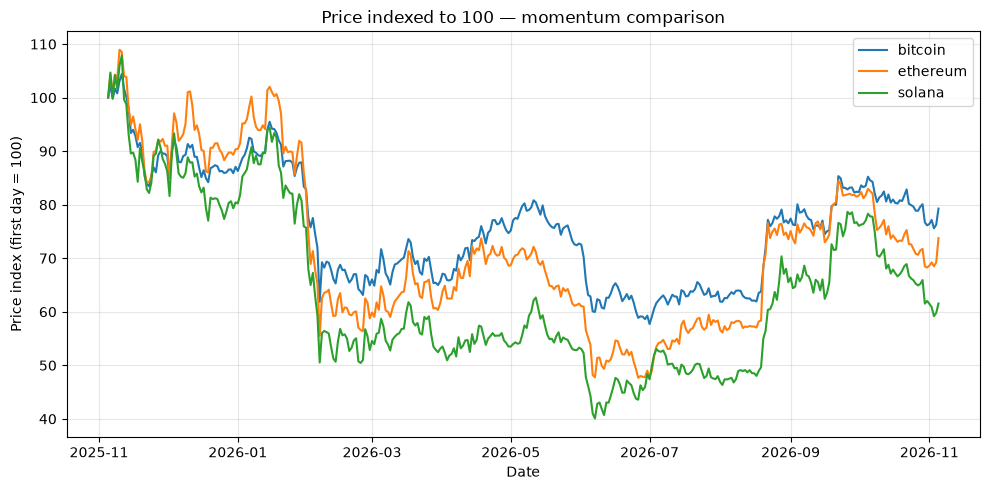

bitcoin: total return -20.7%  (101,481 -> 80,443 USD)
ethereum: total return -26.2%  (3,285 -> 2,423 USD)
solana: total return -38.5%  (155 -> 96 USD)


In [2]:
idx = daily.copy()
idx['indexed'] = idx.groupby('coin')['price'].transform(lambda s: s / s.iloc[0] * 100)
fig, ax = plt.subplots(figsize=(10, 5))
for coin, g in idx.groupby('coin'):
    ax.plot(g['date'], g['indexed'], label=coin)
ax.set_title('Price indexed to 100 — momentum comparison')
ax.set_xlabel('Date'); ax.set_ylabel('Price index (first day = 100)')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
# Independent check of total return
for coin, g in daily.groupby('coin'):
    print(f"{coin}: total return {(g['price'].iloc[-1] / g['price'].iloc[0] - 1):+.1%}  "
          f"({g['price'].iloc[0]:,.0f} -> {g['price'].iloc[-1]:,.0f} USD)")

## Q2 — Volatility & drawdown: which coin was steadier, and how deep were the falls?

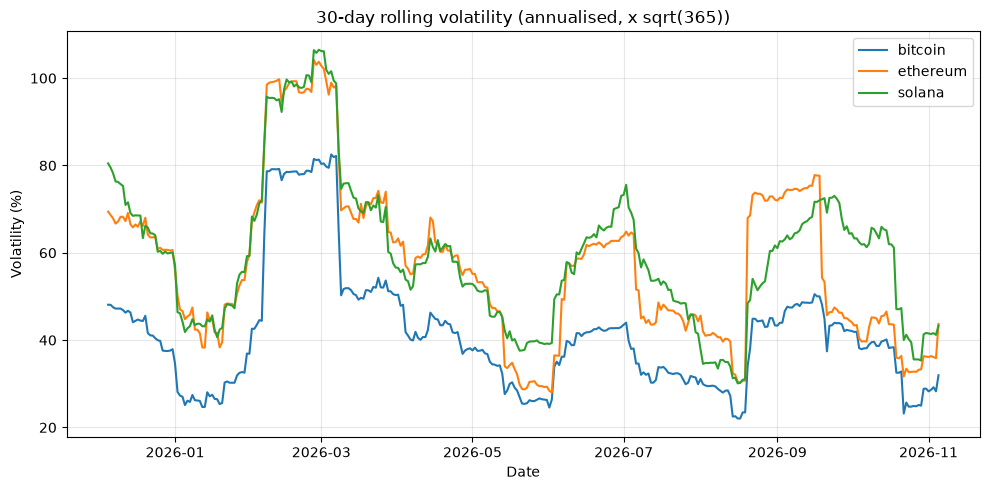

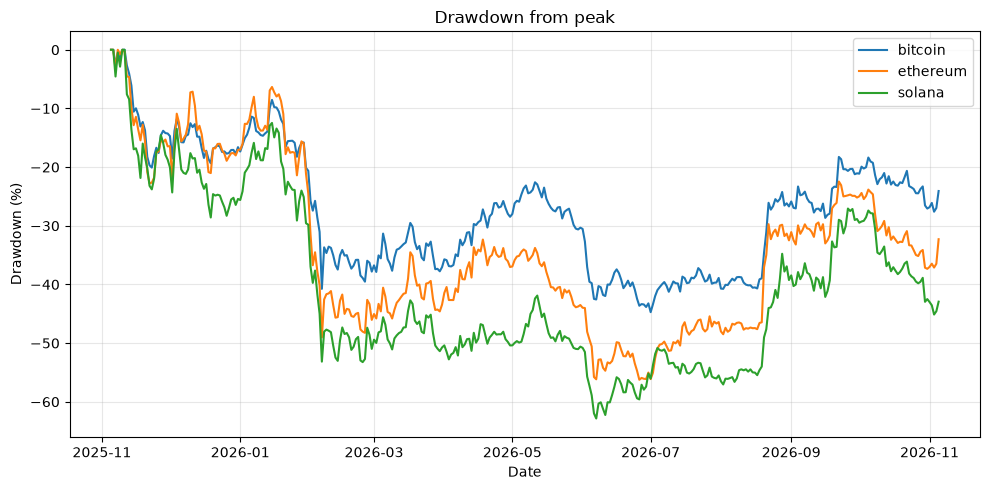

          mean    max
coin                 
bitcoin   41.5   82.5
ethereum  57.4  104.2
solana    59.7  106.5
Max drawdown per coin:
coin
bitcoin    -44.72
ethereum   -56.24
solana     -62.85
Name: drawdown, dtype: float64


In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
for coin, g in metrics.groupby('coin'):
    ax.plot(g['date'], g['vol_30d_annualised'] * 100, label=coin)
ax.set_title('30-day rolling volatility (annualised, x sqrt(365))')
ax.set_xlabel('Date'); ax.set_ylabel('Volatility (%)')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(10, 5))
for coin, g in metrics.groupby('coin'):
    ax.plot(g['date'], g['drawdown'] * 100, label=coin)
ax.set_title('Drawdown from peak')
ax.set_xlabel('Date'); ax.set_ylabel('Drawdown (%)')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
print(metrics.groupby('coin')['vol_30d_annualised'].agg(['mean', 'max']).mul(100).round(1))
print('Max drawdown per coin:')
print(metrics.groupby('coin')['drawdown'].min().mul(100).round(2))

### Manual validation — BTC max drawdown (independent of `compute_metrics`)

Find the peak price and the lowest price after it, then compute `(trough / peak − 1)` by hand and compare with the pipeline's `drawdown` column. If they disagree, the pipeline is wrong — not the hand check.

In [4]:
btc = daily[daily['coin'] == 'bitcoin'].sort_values('date').reset_index(drop=True)
peak_idx = int(btc['price'].idxmax())  # highest price in the window
# The drawdown trough is the lowest price AFTER the running peak, so recompute properly:
running_max = btc['price'].cummax()
dd_manual = btc['price'] / running_max - 1
trough_idx = int(dd_manual.idxmin())
peak_price = float(running_max.iloc[trough_idx])
peak_date = str(btc['date'].iloc[int(btc['price'].iloc[:trough_idx + 1].idxmax())])
trough_price = float(btc['price'].iloc[trough_idx])
trough_date = str(btc['date'].iloc[trough_idx])
manual_mdd = trough_price / peak_price - 1
pipeline_mdd = float(metrics[metrics['coin'] == 'bitcoin']['drawdown'].min())
print(f'Peak:   ${peak_price:,.2f} on {peak_date}')
print(f'Trough: ${trough_price:,.2f} on {trough_date}')
print(f'Manual max drawdown:   {manual_mdd:.4%}')
print(f'Pipeline max drawdown: {pipeline_mdd:.4%}')
print(f'Match: {abs(manual_mdd - pipeline_mdd) < 1e-9}')
assert abs(manual_mdd - pipeline_mdd) < 1e-9, 'Manual check disagrees with pipeline!'

Peak:   $105,951.50 on 2025-11-11 00:00:00
Trough: $58,566.09 on 2026-07-01 00:00:00
Manual max drawdown:   -44.7237%
Pipeline max drawdown: -44.7237%
Match: True


## Q3 — Liquidity: did volume spike, dry up, or stay flat around the biggest moves?

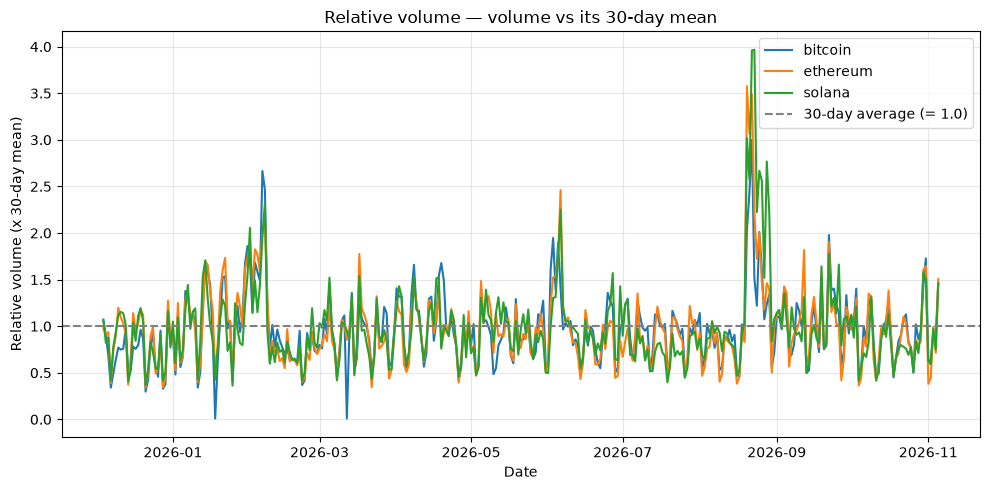

Mean turnover (volume / market cap) per coin:
coin
bitcoin     0.0245
ethereum    0.0610
solana      0.0609
Name: turnover, dtype: float64
Mean relative volume per coin:
coin
bitcoin     0.96
ethereum    0.97
solana      0.98
Name: relative_volume, dtype: float64


In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
for coin, g in metrics.groupby('coin'):
    ax.plot(g['date'], g['relative_volume'], label=coin)
ax.axhline(1.0, color='grey', ls='--', label='30-day average (= 1.0)')
ax.set_title('Relative volume — volume vs its 30-day mean')
ax.set_xlabel('Date'); ax.set_ylabel('Relative volume (x 30-day mean)')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
print('Mean turnover (volume / market cap) per coin:')
print(metrics.groupby('coin')['turnover'].mean().round(4))
print('Mean relative volume per coin:')
print(metrics.groupby('coin')['relative_volume'].mean().round(2))

## Correlation — BTC vs ETH daily returns

In [6]:
piv = metrics.pivot(index='date', columns='coin', values='daily_return')
print('Full-window BTC-ETH correlation:', round(float(piv['bitcoin'].corr(piv['ethereum'])), 3))
print('Latest 90-day rolling correlation:', round(float(piv['bitcoin'].rolling(90).corr(piv['ethereum']).iloc[-1]), 3))
print(piv.corr().round(3))

Full-window BTC-ETH correlation: 0.906
Latest 90-day rolling correlation: 0.89
coin      bitcoin  ethereum  solana
coin                               
bitcoin     1.000     0.906   0.869
ethereum    0.906     1.000   0.875
solana      0.869     0.875   1.000


## Summary table

In [7]:
rows = []
for coin, g in daily.groupby('coin'):
    mg = metrics[metrics['coin'] == coin]
    rows.append({'coin': coin,
                 'total_return': g['price'].iloc[-1] / g['price'].iloc[0] - 1,
                 'mean_vol_30d_ann': mg['vol_30d_annualised'].mean(),
                 'max_vol_30d_ann': mg['vol_30d_annualised'].max(),
                 'max_drawdown': mg['drawdown'].min(),
                 'mean_rel_volume': mg['relative_volume'].mean(),
                 'mean_turnover': mg['turnover'].mean()})
summary = pd.DataFrame(rows)
print(summary.round(4).to_string(index=False))
summary

    coin  total_return  mean_vol_30d_ann  max_vol_30d_ann  max_drawdown  mean_rel_volume  mean_turnover
 bitcoin       -0.2073            0.4153           0.8253       -0.4472           0.9630         0.0245
ethereum       -0.2624            0.5741           1.0418       -0.5624           0.9675         0.0610
  solana       -0.3846            0.5969           1.0650       -0.6285           0.9772         0.0609


,coin,total_return,mean_vol_30d_ann,max_vol_30d_ann,max_drawdown,mean_rel_volume,mean_turnover
0,bitcoin,-0.207311,0.415303,0.825257,-0.447237,0.963045,0.024531
1,ethereum,-0.262432,0.574061,1.041828,-0.562421,0.967498,0.061030
2,solana,-0.384570,0.596907,1.065018,-0.628521,0.977190,0.060876
